# Viral post predictor: merging 6 datasets

Goal: tell if a post will land in the **top third of engagement**, from its platform and format.

Plan: load everything, clean, merge what can really be merged, **test which data actually carries signal**, then train on what helps.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, RepeatedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import roc_auc_score, accuracy_score

## 1. Load and understand each file

In [2]:
raw = "../data/raw/"
viral = pd.read_csv(raw + "Cleaned_Viral_Social_Media_Trends.csv")
viral_nodate = pd.read_csv(raw + "Viral_Social_Media_Trends.csv")
tweets = pd.read_csv(raw + "sentimentdataset.csv")
accounts = pd.read_csv(raw + "Social_Media_Engagement.csv")
users = pd.read_csv(raw + "social-media.csv")
posts100 = pd.read_csv(raw + "social_media_engagement1.csv")

pd.DataFrame({
    "file": ["Cleaned_Viral_Social_Media_Trends", "Viral_Social_Media_Trends", "sentimentdataset", "social_media_engagement1", "Social_Media_Engagement", "social-media"],
    "rows": [len(viral), len(viral_nodate), len(tweets), len(posts100), len(accounts), len(users)],
    "one row is a": ["post", "post", "post", "post", "account", "user"],
})

,file,rows,one row is a
0,Cleaned_Viral_Social_Media_Trends,5000,post
1,Viral_Social_Media_Trends,5000,post
2,sentimentdataset,732,post
3,social_media_engagement1,100,post
4,Social_Media_Engagement,10016,account
5,social-media,63,user


Only **post-level** files can be merged into one post model. The account file (followers, ad spend) and the user file (age, usage time) describe other things: putting them in the same table would mix units and create nonsense.

## 2. Cleaning

In [3]:
print("Viral files identical apart from the date:", viral.drop(columns="Post_Date").equals(viral_nodate))
print("Duplicate account rows:", accounts.duplicated().sum())
accounts = accounts.drop_duplicates()
print("Missing values:", int(viral.isna().sum().sum() + tweets.isna().sum().sum() + accounts.isna().sum().sum() + users.isna().sum().sum() + posts100.isna().sum().sum()))

Viral files identical apart from the date: True
Duplicate account rows: 16
Missing values: 0


The two viral files are the same 5,000 posts, so I keep only the one with dates (merging both would count every post twice).
Usernames and user IDs are not used anywhere.

## 3. Merge the post-level files into one table

In [4]:
format_map = {"Video": "video", "Reel": "video", "Shorts": "video", "Tweet": "text", "Post": "other", "Live Stream": "other"}

a = pd.DataFrame({
    "source": "viral5000", "platform": viral["Platform"], "format": viral["Content_Type"].map(format_map),
    "sentiment": "unknown", "region": viral["Region"], "hashtag": viral["Hashtag"],
    "interactions": viral["Likes"] + viral["Shares"] + viral["Comments"],
})
b = pd.DataFrame({
    "source": "tweets732", "platform": tweets["Platform"].str.strip(), "format": "unknown",
    "sentiment": tweets["Sentiment"].str.strip(), "region": tweets["Country"].str.strip(),
    "hashtag": tweets["Hashtags"].str.split().str[0], "interactions": tweets["Likes"] + tweets["Retweets"],
})
c = pd.DataFrame({
    "source": "posts100", "platform": posts100["platform"], "format": posts100["post_type"],
    "sentiment": posts100["sentiment_score"], "region": "unknown", "hashtag": "unknown",
    "interactions": posts100["likes"] + posts100["comments"] + posts100["shares"],
})
posts = pd.concat([a, b, c], ignore_index=True)

# the sources have very different scales, so "viral" = top third INSIDE each source
posts["rank"] = posts.groupby("source")["interactions"].rank(pct=True)
posts["viral"] = (posts["rank"] > 2 / 3).astype(int)

os.makedirs("../data/processed", exist_ok=True)
posts.to_csv("../data/processed/posts_merged.csv", index=False)
print(posts.shape)
posts.groupby("source").agg(posts=("viral", "size"), median_interactions=("interactions", "median"), viral_share=("viral", "mean")).round(2)

(5832, 9)


,posts,median_interactions,viral_share
source,,,
posts100,100,2612.5,0.34
tweets732,732,65.0,0.33
viral5000,5000,327743.5,0.33


## 4. Exploration

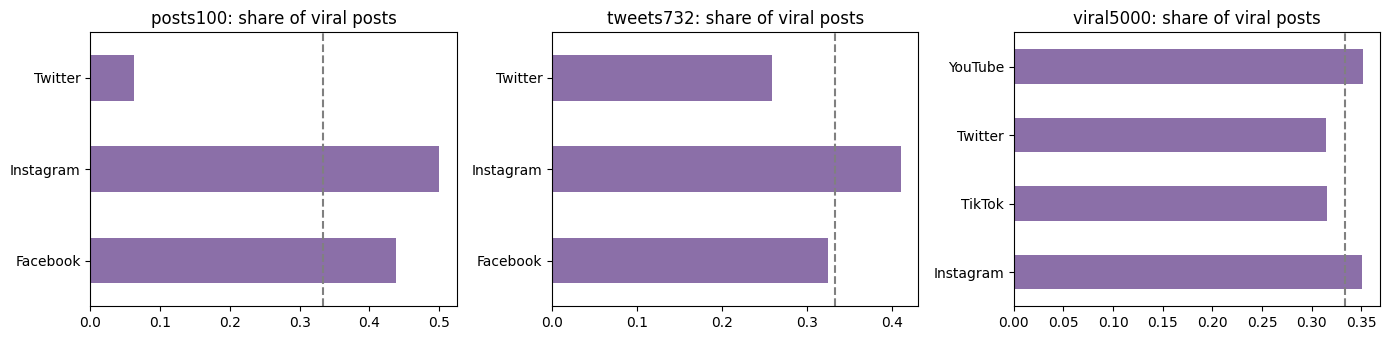

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for axis, (name, g) in zip(ax, posts.groupby("source")):
    g.groupby("platform")["viral"].mean().plot.barh(ax=axis, color="#8b6fa8")
    axis.axvline(1 / 3, color="gray", linestyle="--")
    axis.set_title(name + ": share of viral posts")
    axis.set_ylabel("")
plt.tight_layout()
plt.show()

In [6]:
# in the 5000-post file, do views, likes and shares move together?
print(viral[["Views", "Likes", "Shares", "Comments"]].corr().round(2))
viral["total"] = viral["Likes"] + viral["Shares"] + viral["Comments"]
print(viral.groupby("Engagement_Level")["total"].agg(["min", "max"]))

          Views  Likes  Shares  Comments
Views      1.00  -0.00    0.01     -0.01
Likes     -0.00   1.00    0.01     -0.01
Shares     0.01   0.01    1.00     -0.00
Comments  -0.01  -0.01   -0.00      1.00
                    min     max
Engagement_Level               
High              16683  635139
Low               12418  618596
Medium            20692  630930


Warning signs in the 5,000-post file: views and likes are uncorrelated, and its "High / Medium / Low" labels overlap completely (a "Low" post can have more interactions than a "High" one). Real data doesn't look like that. The next step checks it properly.

## 5. Does each source contain signal? (cross-validated AUC, 0.5 = random)

In [7]:
def model(cols, C=0.3):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cols)])
    return make_pipeline(pre, LogisticRegression(C=C, max_iter=2000))

def cv_auc(df, cols, repeats=10):
    scores = []
    for r in range(repeats):
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(df, df["viral"]):
            m = model(cols).fit(df.iloc[tr][cols], df.iloc[tr]["viral"])
            scores.append(roc_auc_score(df.iloc[te]["viral"], m.predict_proba(df.iloc[te][cols])[:, 1]))
    return np.mean(scores)

rows = []
for name, g in posts.groupby("source"):
    all_cols = [c for c in ["platform", "format", "sentiment", "region", "hashtag"] if g[c].nunique() > 1]
    rows.append([name, cv_auc(g, ["platform"] if name == "tweets732" else ["platform", "format"]), cv_auc(g, all_cols)])
audit = pd.DataFrame(rows, columns=["source", "AUC platform (+format)", "AUC all features"]).round(3)
audit

,source,AUC platform (+format),AUC all features
0,posts100,0.735,0.721
1,tweets732,0.577,0.705
2,viral5000,0.506,0.503


- **posts100**: real signal (platform and format).
- **tweets732**: some signal.
- **viral5000**: AUC about 0.50 with every combination of features. Its labels behave like random noise, so no model can learn from it.

## 6. Does adding the extra data improve predictions on the 100 posts?

In [8]:
cols = ["platform", "format"]
base = posts[posts["source"] == "posts100"].reset_index(drop=True)

def test_extra(extra, weight, repeats=20):
    aucs = []
    for r in range(repeats):
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(base, base["viral"]):
            train = pd.concat([base.iloc[tr], extra])
            w = np.r_[np.ones(len(tr)), np.full(len(extra), weight)]
            m = model(cols)
            m.fit(train[cols], train["viral"], logisticregression__sample_weight=w)
            aucs.append(roc_auc_score(base.iloc[te]["viral"], m.predict_proba(base.iloc[te][cols])[:, 1]))
    return np.mean(aucs)

t = posts[posts["source"] == "tweets732"]
v = posts[posts["source"] == "viral5000"]
empty = posts.iloc[:0]

results = [["100 posts only", 1.0, test_extra(empty, 1)]]
for w in [0.05, 0.1, 0.25, 0.5, 1]:
    results.append(["+ tweets732", w, test_extra(t, w)])
for w in [0.05, 1]:
    results.append(["+ viral5000", w, test_extra(v, w)])
table = pd.DataFrame(results, columns=["training data", "weight of extra rows", "AUC on held-out posts100"]).round(3)
table

,training data,weight of extra rows,AUC on held-out posts100
0,100 posts only,1.00,0.735
1,+ tweets732,0.05,0.742
2,+ tweets732,0.10,0.743
3,+ tweets732,0.25,0.735
4,+ tweets732,0.50,0.724
5,+ tweets732,1.00,0.720
6,+ viral5000,0.05,0.669
7,+ viral5000,1.00,0.587


Test: the held-out rows are always from the 100 posts, because they are the posts the model will be used on.
The 5,000 random-label posts **hurt** the model, even with a small weight. The tweets are roughly neutral: the gain, if any, is within the noise.
So "more data" is only better when the data is real.

## 7. Account and user files (separate analyses)

In [9]:
print(accounts[["Follower Count", "Posts Per Week", "Ad Spend (USD)", "Conversion Rate", "Campaign Reach", "Engagement Rate"]].corr()["Engagement Rate"].round(3))
print(accounts.groupby("Platform")["Engagement Rate"].mean().round(4))
print(users[["UsageDuraiton", "Age", "TotalLikes"]].corr().round(2))

Follower Count    -0.017
Posts Per Week     0.017
Ad Spend (USD)     0.007
Conversion Rate   -0.004
Campaign Reach     0.010
Engagement Rate    1.000
Name: Engagement Rate, dtype: float64
Platform
Facebook     0.0864
Instagram    0.0869
LinkedIn     0.0861
TikTok       0.0865
Twitter      0.0877
Name: Engagement Rate, dtype: float64
               UsageDuraiton   Age  TotalLikes
UsageDuraiton           1.00 -0.64        0.69
Age                    -0.64  1.00       -0.48
TotalLikes              0.69 -0.48        1.00


- Accounts (10,000): nothing explains the engagement rate (all correlations near zero, same average rate on every platform). Another file that looks random.
- Users (63): usage time and likes are related (the more time, the more likes), and age goes the other way. Interesting but tiny, and it is about people, not posts, so it can't feed the post model.

## 8. Final model

In [10]:
# the classifier uses the 100 posts plus the tweets at the weight that worked best
best = table[table["training data"] == "+ tweets732"].sort_values("AUC on held-out posts100").iloc[-1]
w_tweets = float(best["weight of extra rows"])
print("tweets weight:", w_tweets)

train = pd.concat([base, t])
weights = np.r_[np.ones(len(base)), np.full(len(t), w_tweets)]

# honest evaluation: only held-out rows of the 100 posts
aucs, accs, base_accs = [], [], []
for r in range(20):
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=r).split(base, base["viral"]):
        tr_df = pd.concat([base.iloc[tr], t])
        w = np.r_[np.ones(len(tr)), np.full(len(t), w_tweets)]
        m = model(cols); m.fit(tr_df[cols], tr_df["viral"], logisticregression__sample_weight=w)
        p = m.predict_proba(base.iloc[te][cols])[:, 1]
        aucs.append(roc_auc_score(base.iloc[te]["viral"], p))
        accs.append(accuracy_score(base.iloc[te]["viral"], p > 0.5))
        base_accs.append(accuracy_score(base.iloc[te]["viral"], np.zeros(len(te))))
print("AUC:", round(np.mean(aucs), 3), "| accuracy:", round(np.mean(accs), 3), "| always 'not viral':", round(np.mean(base_accs), 3))

clf = model(cols); clf.fit(train[cols], train["viral"], logisticregression__sample_weight=weights)

tweets weight: 0.1


AUC: 0.743 | accuracy: 0.689 | always 'not viral': 0.66


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformer

In [11]:
# expected engagement (log scale): only the 100 posts, because the other sources use other scales
y_log = np.log1p(base["interactions"])
reg = make_pipeline(ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cols)]), Ridge(alpha=10))
r2 = cross_val_score(reg, base[cols], y_log, cv=RepeatedKFold(n_splits=5, n_repeats=20, random_state=0), scoring="r2").mean()
resid = y_log - cross_val_predict(reg, base[cols], y_log, cv=5)
q10, q90 = np.quantile(resid, [0.1, 0.9])
reg.fit(base[cols], y_log)
print("R2:", round(r2, 3), "| 80% range on log scale:", round(q10, 2), "to", round(q90, 2))

R2: 0.115 | 80% range on log scale: -1.02 to 0.71


## 9. Export for the website

In [12]:
names = [n.replace("cat__", "") for n in clf[0].get_feature_names_out()]
limit = float(base["interactions"].quantile(0.67))
model_json = {
    "features": names,
    "clf_coef": clf[1].coef_[0].round(4).tolist(), "clf_intercept": round(float(clf[1].intercept_[0]), 4),
    "reg_coef": reg[1].coef_.round(4).tolist(), "reg_intercept": round(float(reg[1].intercept_), 4),
    "q10": round(float(q10), 4), "q90": round(float(q90), 4), "viral_threshold": round(limit),
    "metrics": {"auc": round(float(np.mean(aucs)), 3), "accuracy": round(float(np.mean(accs)), 3),
                "baseline_accuracy": round(float(np.mean(base_accs)), 3), "r2": round(float(r2), 3),
                "n": len(base), "n_extra": len(t), "n_rejected": len(v)},
}
open("../public/model.js", "w").write("const M=" + json.dumps(model_json) + ";")
model_json["metrics"]

{'auc': 0.743,
 'accuracy': 0.689,
 'baseline_accuracy': 0.66,
 'r2': 0.115,
 'n': 100,
 'n_extra': 732,
 'n_rejected': 5000}

## Conclusion

- Six files, but only three describe posts, and one of those (5,000 posts) has labels that behave like random noise.
- Merging everything makes predictions **worse** (AUC on the real posts drops from about 0.73 to about 0.59). The final model uses the 100 real posts plus the tweets at a low weight. That small gain (0.735 to 0.743) is within the noise, and the weight was picked on the same data, so treat it as "not harmful", not as "proven better".
- The only dependable signals are the platform and the format. Accuracy stays close to the "always not viral" baseline, so the tool compares ideas; it is not a verdict.
- To really improve it: more real posts with creator-level features (followers, length, hashtags, caption), for example from your own account analytics export.